## EN4554 Assignment 2: CNNs (Task 3 of 4: Regularisation and residual connections)


##### **Name:** *Sasanka D.M.I.*  
##### **Index Number:** *220583J*


### Use of AI-Assisted Coding Tools

ChatGPT was used as an AI-assisted tool to review the implementation, identify potential issues, and help interpret the experimental results. The tool provided suggestions for improving code correctness and understanding the effects of different model architectures, optimization strategies, and regularization techniques. The code was reviewed and executed by the student, who is responsible for understanding the implementation, verifying the results, and ensuring the accuracy of the submitted work.

## Setup (same split and normalisation as before)

In [1]:
import numpy as np, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import datasets

In [2]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Using device:', device)

def set_seed(s=0):
    torch.manual_seed(s); np.random.seed(s); torch.cuda.manual_seed_all(s)
set_seed(0)

# CIFAR-10 training set only. The test set is NOT loaded (it is used once, in Task 4).
full = datasets.CIFAR10('./data', train=True, download=True)
X = torch.tensor(full.data).float() / 255          # (50000, 32, 32, 3)
X = X.permute(0, 3, 1, 2)                          # (50000, 3, 32, 32)
y = torch.tensor(full.targets)

# 45k train / 5k validation split with a fixed seed
perm = torch.randperm(50000, generator=torch.Generator().manual_seed(0))
tr, va = perm[:45000], perm[45000:]
Xtr, ytr, Xva, yva = X[tr], y[tr], X[va], y[va]

# per-channel normalisation using TRAINING statistics only
mean = Xtr.mean((0, 2, 3), keepdim=True)
std  = Xtr.std((0, 2, 3), keepdim=True)
Xtr = (Xtr - mean) / std
Xva = (Xva - mean) / std

# flattened copies on the device for the MLP
Xtr_f = Xtr.flatten(1).to(device); ytr = ytr.to(device)
Xva_f = Xva.flatten(1).to(device); yva = yva.to(device)
print(Xtr_f.shape, Xva_f.shape)

Using device: cuda
torch.Size([45000, 3072]) torch.Size([5000, 3072])


## Shared helpers: augmentations (written by me), evaluation and a training loop
After normalisation the mean pixel is 0, so zero padding and zero cutout patches mean "average colour".

In [3]:
def flip_crop(x, pad=4):
    # random horizontal flip + random 32x32 crop from the zero-padded image (per sample)
    B = x.size(0)
    flip = (torch.rand(B, device=x.device) < 0.5).view(B, 1, 1, 1)
    x = torch.where(flip, x.flip(3), x)
    xp = F.pad(x, (pad, pad, pad, pad))
    oy = torch.randint(0, 2 * pad + 1, (B,)).tolist()
    ox = torch.randint(0, 2 * pad + 1, (B,)).tolist()
    return torch.stack([xp[i, :, oy[i]:oy[i] + 32, ox[i]:ox[i] + 32] for i in range(B)])


In [4]:
def cutout(x, size=8):
    # zero a size x size square at a random centre (may be clipped by the border)
    B, _, H, W = x.shape
    cy = torch.randint(0, H, (B, 1, 1), device=x.device)
    cx = torch.randint(0, W, (B, 1, 1), device=x.device)
    ys = torch.arange(H, device=x.device).view(1, H, 1)
    xs = torch.arange(W, device=x.device).view(1, 1, W)
    h = size // 2
    inside = (ys >= cy - h) & (ys < cy + h) & (xs >= cx - h) & (xs < cx + h)   # (B, H, W)
    return x * (~inside).unsqueeze(1)


In [6]:
# mixup is done inside the training loop: mix images with lam ~ Beta(a, a), mix the two losses with lam

@torch.no_grad()
def evaluate(model, X, t):
    model.eval()
    correct = sum((model(X[i:i+1000]).argmax(1) == t[i:i+1000]).sum().item()
                  for i in range(0, len(X), 1000))
    return correct / len(X)


In [7]:
def train_model(model, Xt, yt, epochs, lr=0.05, wd=0.0, bs=128,
                flip_crop_on=False, cutout_on=False, mixup_on=False, eval_train=True):
    model = model.to(device)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=wd)
    hist = dict(train_loss=[], train_acc=[], val_acc=[])
    for ep in range(epochs):
        model.train()
        idx = torch.randperm(len(Xt), device=device)
        total, n = 0.0, 0
        for i in range(0, len(idx), bs):
            b = idx[i:i+bs]
            xb, yb = Xt[b], yt[b]
            if flip_crop_on: xb = flip_crop(xb)
            if cutout_on:    xb = cutout(xb)
            if mixup_on:
                lam = np.random.beta(0.4, 0.4)
                p = torch.randperm(len(xb), device=device)
                out = model(lam * xb + (1 - lam) * xb[p])
                loss = lam * F.cross_entropy(out, yb) + (1 - lam) * F.cross_entropy(out, yb[p])
            else:
                loss = F.cross_entropy(model(xb), yb)
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(b); n += len(b)
        hist['train_loss'].append(total / n)
        hist['val_acc'].append(evaluate(model, Xva, yva))
        if eval_train:                       # accuracy on the CLEAN training images
            hist['train_acc'].append(evaluate(model, Xt, yt))
        if np.isnan(hist['train_loss'][-1]):  # diverged
            break
    return hist

In [8]:
# Quick visual check of my augmentations (image 0 of the training set)
def show(img):
    return (img * std[0] + mean[0]).clamp(0, 1).permute(1, 2, 0).cpu().numpy()


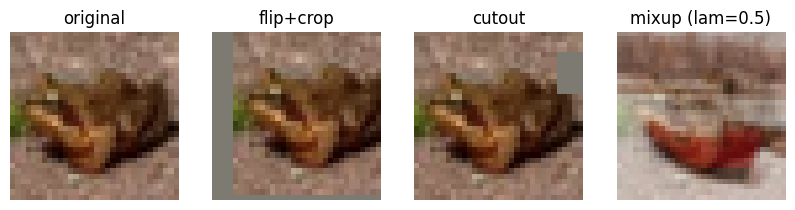

In [9]:
x0 = Xtr[:1]
set_seed(1)
demo = {'original': x0, 'flip+crop': flip_crop(x0), 'cutout': cutout(x0),
        'mixup (lam=0.5)': 0.5 * x0 + 0.5 * Xtr[1:2]}
fig, ax = plt.subplots(1, 4, figsize=(10, 2.8))
for a, (name, im) in zip(ax, demo.items()):
    a.imshow(show(im[0])); a.set_title(name); a.axis('off')
plt.show()

## Task 3(a): Regularisation on 5k training images

Train accuracy is measured on the clean (un-augmented) 5k training images; all numbers are from the last epoch.
Settings: weight decay 5e-3, dropout 0.5 (before the linear layer), cutout 8x8, mixup alpha 0.4. These can be tuned on the validation set.

In [10]:
from torch import nn

In [11]:
def make_cnn(dropout=0.0):
    def block(i, o):
        return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False),
                             nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
    return nn.Sequential(block(3, 32), block(32, 64), block(64, 128),
                         nn.Flatten(), nn.Dropout(dropout), nn.Linear(128 * 4 * 4, 10))

In [13]:
Xtr = Xtr.to(device)
Xva = Xva.to(device)

Xs, ys = Xtr[:5000], ytr[:5000]

configs = {
    'baseline':     {},
    'weight decay': dict(wd=5e-3),
    'dropout':      dict(dropout=0.5),
    'flip+crop':    dict(flip_crop_on=True),
    'cutout':       dict(cutout_on=True),
    'mixup':        dict(mixup_on=True),
    'all combined': dict(wd=5e-3, dropout=0.5, flip_crop_on=True, cutout_on=True, mixup_on=True),
}
hists = {}
for name, cfg in configs.items():
    cfg = dict(cfg)
    p = cfg.pop('dropout', 0.0)
    set_seed(0)
    hists[name] = train_model(make_cnn(p), Xs, ys, epochs=40, **cfg)
    print('done:', name)

print(f"\n{'config':14s} {'train acc':>9s} {'val acc':>8s} {'gap':>7s}")

for name, h in hists.items():
    tr_a, va_a = h['train_acc'][-1], h['val_acc'][-1]
    print(f"{name:14s} {tr_a:9.4f} {va_a:8.4f} {tr_a - va_a:7.4f}")

done: baseline
done: weight decay
done: dropout
done: flip+crop
done: cutout
done: mixup
done: all combined

config         train acc  val acc     gap
baseline          0.6200   0.4780  0.1420
weight decay      0.5920   0.4692  0.1228
dropout           0.1914   0.1824  0.0090
flip+crop         0.5554   0.5196  0.0358
cutout            0.6106   0.5110  0.0996
mixup             0.4150   0.3682  0.0468
all combined      0.4350   0.4254  0.0096


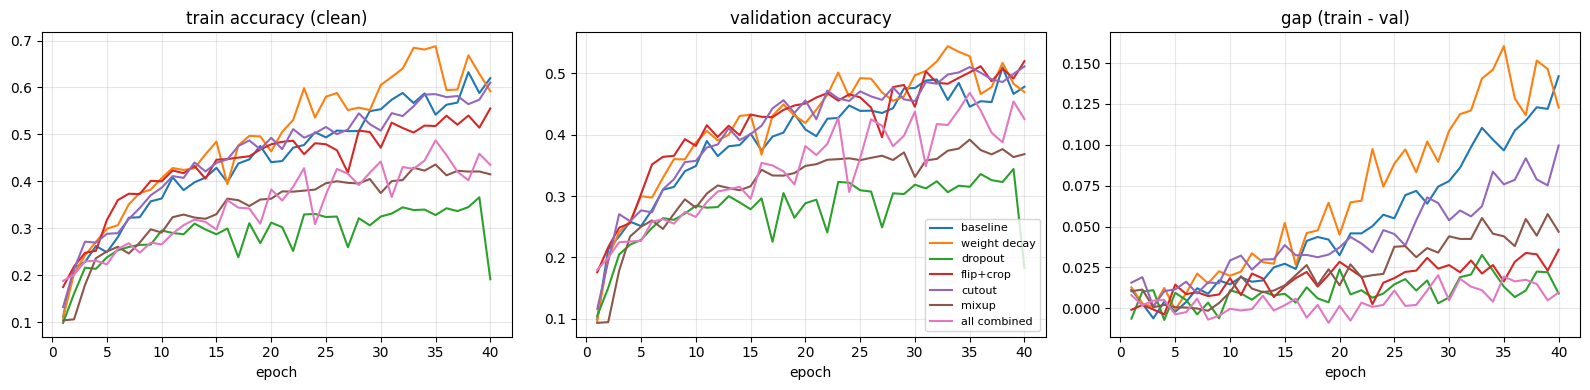

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

for name, h in hists.items():
    ep = range(1, len(h['val_acc']) + 1)
    gap = np.array(h['train_acc']) - np.array(h['val_acc'])
    ax[0].plot(ep, h['train_acc'], label=name)
    ax[1].plot(ep, h['val_acc'], label=name)
    ax[2].plot(ep, gap, label=name)

for a, t in zip(ax, ['train accuracy (clean)', 'validation accuracy', 'gap (train - val)']):
    a.set_title(t); a.set_xlabel('epoch'); a.grid(alpha=0.3)

ax[1].legend(fontsize=8)
plt.tight_layout();
plt.show()


#### Discussion

- Baseline: Achieves 47.80% validation accuracy, with a 14.20 percentage-point gap, suggesting some overfitting.
- Weight decay: Reduces the gap slightly, but validation accuracy also decreases. It does not improve generalization in this experiment.
- Dropout: Both training and validation accuracy are very low. A dropout rate of 0.5 may be too strong for this model and limited training setup.
- Flip + crop: Achieves the highest validation accuracy and reduces the gap to 3.58 percentage points, suggesting that data augmentation improves generalization.
- Cutout: Improves validation accuracy to 51.10%, showing that masking image regions can encourage the model to learn more robust features.
- Mixup: Produces lower validation accuracy than the baseline. The model may need more training or different mixup settings to benefit from this technique.
- All combined: Has a small gap, but validation accuracy is only 42.54%. Combining regularization methods does not necessarily improve performance because their effects can be too strong together.

So in conslusion, Flip + crop performs best among the tested configurations. The results show that reducing the train-validation gap alone does not guarantee better accuracy. Regularization must be balanced to improve generalization without causing underfitting.

## Task 3(b): Plain vs residual CIFAR networks, depth 6n+2 = 8, 20, 56

Training: full 45k training set, no augmentation (to look at optimisation), SGD momentum 0.9, lr 0.05, 15 epochs.

In [16]:
class Block(nn.Module):
    def __init__(self, c_in, c_out, stride, residual):
        super().__init__()
        self.conv1 = nn.Conv2d(c_in, c_out, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(c_out)
        self.residual, self.stride, self.extra = residual, stride, c_out - c_in

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:                                   # the only difference
            sc = x[:, :, ::self.stride, ::self.stride]      # subsample
            sc = F.pad(sc, (0, 0, 0, 0, 0, self.extra))     # zero-pad channels
            out = out + sc
        return F.relu(out)

class CifarNet(nn.Module):
    def __init__(self, depth, residual):
        super().__init__()
        n = (depth - 2) // 6
        self.stem = nn.Sequential(nn.Conv2d(3, 16, 3, 1, 1, bias=False), nn.BatchNorm2d(16), nn.ReLU())
        blocks, c_in = [], 16
        for c_out, stride in [(16, 1), (32, 2), (64, 2)]:
            for k in range(n):
                blocks.append(Block(c_in, c_out, stride if k == 0 else 1, residual))
                c_in = c_out
        self.blocks = nn.Sequential(*blocks)
        self.fc = nn.Linear(64, 10)
        for m in self.modules():                            # Kaiming initialisation
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
    def forward(self, x):
        x = self.blocks(self.stem(x))
        return self.fc(x.mean((2, 3)))                      # global average pooling



In [17]:
for d in [8, 20, 56]:
    a, b = CifarNet(d, False), CifarNet(d, True)
    print(d, 'params plain/residual:', sum(p.numel() for p in a.parameters()),
          sum(p.numel() for p in b.parameters()))

8 params plain/residual: 75290 75290
20 params plain/residual: 269722 269722
56 params plain/residual: 853018 853018


In [18]:
depths = [8, 20, 56]
res = {}                                              # (depth, residual) -> history
for d in depths:
    for residual in [False, True]:
        set_seed(0)
        res[(d, residual)] = train_model(CifarNet(d, residual), Xtr, ytr, epochs=15, eval_train=False)
        h = res[(d, residual)]
        print(f"depth {d:2d} {'residual' if residual else 'plain   '}  "
              f"final train loss {h['train_loss'][-1]:.3f}  val acc {h['val_acc'][-1]:.4f}")

depth  8 plain     final train loss 0.393  val acc 0.7418
depth  8 residual  final train loss 0.420  val acc 0.7288
depth 20 plain     final train loss 0.259  val acc 0.7500
depth 20 residual  final train loss 0.132  val acc 0.7708
depth 56 plain     final train loss 1.176  val acc 0.5084
depth 56 residual  final train loss 0.135  val acc 0.7682


In [25]:
for d in depths:
    print(f"\n{'Epoch':<8}{'Plain Loss':>14}{'Residual Loss':>17}")
    print("-" * 39)

    plain_loss = res[(d, False)]['train_loss']
    residual_loss = res[(d, True)]['train_loss']

    for epoch, (pl, rl) in enumerate(zip(plain_loss, residual_loss), start=1):
        print(f"{epoch:<8}{pl:>14.4f}{rl:>17.4f}")


Epoch       Plain Loss    Residual Loss
---------------------------------------
1               1.5326           1.5359
2               1.1163           1.1214
3               0.9596           0.9622
4               0.8478           0.8616
5               0.7732           0.7873
6               0.7114           0.7303
7               0.6546           0.6746
8               0.6081           0.6338
9               0.5683           0.5961
10              0.5313           0.5607
11              0.4958           0.5208
12              0.4708           0.4982
13              0.4460           0.4712
14              0.4215           0.4480
15              0.3929           0.4196

Epoch       Plain Loss    Residual Loss
---------------------------------------
1               1.6213           1.4241
2               1.1874           0.9520
3               0.9351           0.7590
4               0.7718           0.6217
5               0.6802           0.5415
6               0.6031           0.465

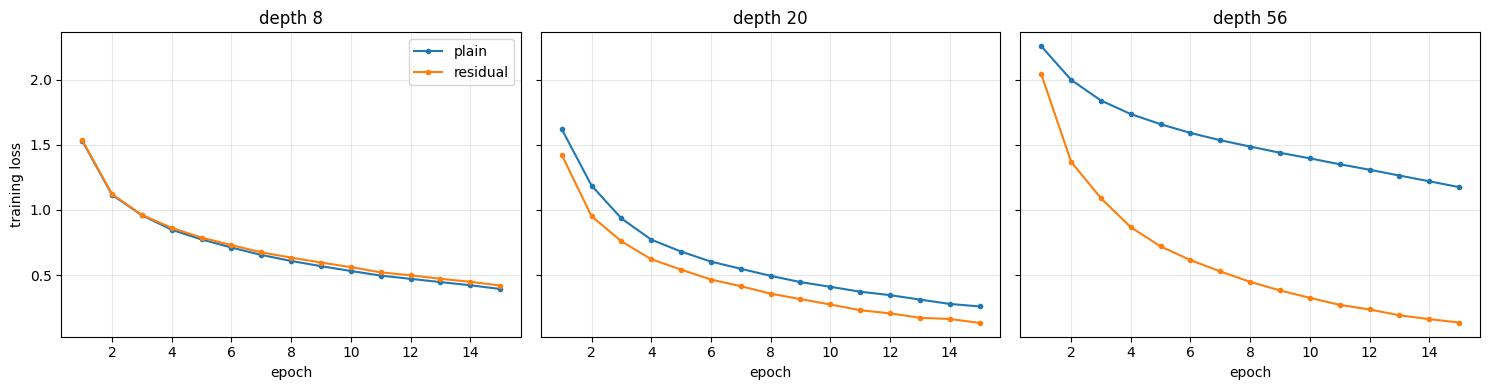

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for a, d in zip(ax, depths):
    for residual, label in [(False, 'plain'), (True, 'residual')]:
        h = res[(d, residual)]
        a.plot(range(1, len(h['train_loss']) + 1), h['train_loss'], marker='o', ms=3, label=label)
    a.set_title(f'depth {d}'); a.set_xlabel('epoch'); a.grid(alpha=0.3)
ax[0].set_ylabel('training loss'); ax[0].legend()
plt.tight_layout(); plt.show()

#### Interpretation of results

- Depth 8: The plain network performs slightly better, with a final training loss of 0.393 compared with 0.420 for the residual network. The residual connection does not provide a clear advantage at this depth.
- Depth 20: The residual network achieves a lower training loss of 0.132, compared with 0.259 for the plain network. Its validation accuracy is also higher, at 77.08%.
- Depth 56: The difference is substantial. The plain network reaches a training loss of 1.176 and validation accuracy of 50.84%, while the residual network reaches a training loss of 0.135 and validation accuracy of 76.82%.


Residual connections provide shortcut paths that allow information and gradients to flow more easily through deeper networks. This helps reduce optimization difficulties as network depth increases. In your results, the plain 56-layer network struggles to minimize its training loss, whereas the residual network continues to learn effectively.

The parameter counts are identical for each plain and residual pair, confirming that the shortcut connections add no trainable parameters in your implementation.

As a conclusion Residual connections offer little benefit at depth 8 in this experiment, but improve optimization considerably at depths 20 and 56. The results demonstrate why residual architectures are particularly useful for training deeper neural networks. These conclusions apply to your chosen training settings and 15 epochs, rather than every possible configuration.